# Week 2 Assessment Mini-Project

Complete all TODOs below. Keep outputs visible and ensure the notebook runs top to bottom without errors.

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

In [41]:
# TODO: Load the dataset with date parsing and set the index
# File: m1-09-assessment.csv

# df = pd.read_csv("m1-09-assessment.csv", parse_dates=["date"])
# df = df.set_index("date")

# TODO: Show head/tail and check info

## Part A: Core Data Handling (TODOs)

- Inspect structure with `info()`, `describe()`, and missing value counts.
- Clean `pm25` by coercing invalid strings to NaN.
- Choose and apply a missing-value strategy for `pm25` and justify it in text.

In [42]:
# TODO: data inspection
# df.info()
# df.describe()
# df.isna().sum()

# TODO: clean pm25
# df["pm25"] = pd.to_numeric(df["pm25"], errors="coerce")

# TODO: handle missing values in pm25 and justify in markdown

1

In [43]:
df = pd.read_csv("m1-09-assessment.csv", parse_dates=["date"])
df = df.set_index("date")

In [44]:
2

2

In [45]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 900 entries, 2023-01-01 to 2023-06-29
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   city          900 non-null    object 
 1   avg_temp_c    863 non-null    float64
 2   humidity_pct  900 non-null    float64
 3   pm25          850 non-null    float64
dtypes: float64(3), object(1)
memory usage: 35.2+ KB
None


In [46]:
print(df.describe())

       avg_temp_c  humidity_pct        pm25
count  863.000000    900.000000  850.000000
mean     9.259849     64.931011   23.961247
std      9.134278     14.432234   11.856849
min    -15.030000     35.000000    5.000000
25%      1.410000     54.672500   14.090000
50%      9.790000     64.870000   23.710000
75%     16.775000     75.190000   33.427500
max     30.390000     95.000000   60.600000


In [47]:
print(df.isna().sum())

city             0
avg_temp_c      37
humidity_pct     0
pm25            50
dtype: int64


In [48]:
3

3

In [49]:
df.pm25 = pd.to_numeric(df.pm25, errors='coerce')
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 900 entries, 2023-01-01 to 2023-06-29
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   city          900 non-null    object 
 1   avg_temp_c    863 non-null    float64
 2   humidity_pct  900 non-null    float64
 3   pm25          850 non-null    float64
dtypes: float64(3), object(1)
memory usage: 35.2+ KB


4

In [50]:
df['pm25_rolled'] = df.groupby('city')['pm25'].transform(lambda x: x.rolling(window=3, min_periods=1).mean())
df['pm25_filled'] = df['pm25'].fillna(df['pm25_rolled'])
df['pm25_filled'] = df['pm25_filled'].fillna(method='bfill').fillna(method='ffill')
df.drop(columns= ['pm25_rolled'], inplace=True)
df['pm25_filled'].isna().sum()

C:\Users\asifh\AppData\Local\Temp\ipykernel_13824\2106060325.py:3: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df['pm25_filled'] = df['pm25_filled'].fillna(method='bfill').fillna(method='ffill')


np.int64(0)

1. created a new column pm25_rolled for the later on use

2. used groupby('city') for not mixing the different cities' pm25 values later on

3. then used transform to align df with the initial index and using the function lambda with rolling
4. the rolling(window=3).mean() is used to find the mean value of 3 sequential rows for the mid row
5. then i used fillna to replace the missing values in my original pm25 with the corresponding(respect to date) value of pm25_rolled column and assigned them to new column named pm25_filled
6. used ffill and bfill to fill the missing values even after all the steps above, as i dont know the exact index of the missing value i used both ffill and bfill

7. then dropped the column i made for this task whic is pm25_rolled

## Part B: Required Analysis (TODOs)

- Data quality analysis: city with highest % invalid/missing pm25.
- Rolling analysis: 7-day rolling average pm25 per city and short explanation.
- Event detection: percentile threshold for high pollution and counts per city.
- Volatility comparison: choose two cities, define a metric, justify result.
- Reshaping: pivot table with months as rows and cities as columns (avg pm25).

In [51]:
# TODO: analysis tasks
# - data quality by city
# - rolling averages per city
# - percentile-based event counts
# - volatility comparison
# - pivot table by month and city

5

In [52]:
missing_table = df.pivot_table(index='city',
                               values='pm25', 
                               aggfunc=lambda x: x.isna().mean()*100)
print(missing_table, '\n')
print(missing_table.idxmax())

            pm25
city            
Berlin  7.777778
London  2.777778
Madrid  6.666667
Paris   5.000000
Warsaw  5.555556 

pm25    Berlin
dtype: object


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 900 entries, 2023-01-01 to 2023-06-29
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   city          900 non-null    object 
 1   avg_temp_c    863 non-null    float64
 2   humidity_pct  900 non-null    float64
 3   pm25          850 non-null    float64
 4   pm25_filled   900 non-null    float64
dtypes: float64(4), object(1)
memory usage: 42.2+ KB


6

In [54]:
df_rolled = df['pm25'].rolling(window=7).mean()

because the value of pm25 is more likely to be the avg(mean) of the least 7 days, normally as there's no huge gaps between the sequential values it's pssible to predict the next value based on the last 7 days


7

In [55]:
hpt = np.percentile(pd.to_numeric(df['pm25'],
                                errors='coerce').dropna(),
                                70) 
#hpt stands for high pollution threshold
hpt

np.float64(31.756)

In [56]:
df[df.pm25 > hpt].pivot_table(values='pm25', index='city', aggfunc='count')

,pm25
city,
Berlin,50
London,55
Madrid,48
Paris,46
Warsaw,56


8

In [57]:
stats = df.groupby('city')['pm25_filled'].agg(['mean', 'std'])
stats['CV'] = (stats['std'] / stats['mean']) * 100


comparison = stats.loc[['London', 'Warsaw']]
print(comparison)

             mean        std         CV
city                                   
London  24.320028  12.140888  49.921357
Warsaw  23.999528  12.579080  52.413864


9

In [58]:
month_by_city = df.pivot_table(
    values='pm25', 
    index=df.index.to_period('M'), 
    columns='city', 
    aggfunc='mean'
)
print(month_by_city)

city        Berlin     London     Madrid      Paris     Warsaw
date                                                          
2023-01  33.083846  33.275806  33.136000  34.596552  37.239032
2023-02  33.106538  33.769259  34.446087  34.086800  34.240000
2023-03  29.213667  29.737742  30.091667  26.736774  27.489310
2023-04  22.392308  24.864333  21.941034  23.241379  20.749333
2023-05  15.323000  14.220000  14.809310  14.227143  14.432143
2023-06  10.046786   9.376667  10.033333   9.280345   9.610000


## Part C: Aggregations (TODOs)

- Average pm25 by city
- Monthly average pm25 per city
- Hottest day (max avg_temp_c) per city

In [59]:
# TODO: aggregation tasks
# avg_pm25_by_city = ...
# monthly_avg_pm25 = ...
# hottest_day_per_city = ...

10

In [60]:
monthly = df.pivot_table(
    values='pm25', 
    index=df.index.to_period('M'), 
    columns='city', 
    aggfunc='mean'
)
print(monthly)

city        Berlin     London     Madrid      Paris     Warsaw
date                                                          
2023-01  33.083846  33.275806  33.136000  34.596552  37.239032
2023-02  33.106538  33.769259  34.446087  34.086800  34.240000
2023-03  29.213667  29.737742  30.091667  26.736774  27.489310
2023-04  22.392308  24.864333  21.941034  23.241379  20.749333
2023-05  15.323000  14.220000  14.809310  14.227143  14.432143
2023-06  10.046786   9.376667  10.033333   9.280345   9.610000


11

In [61]:
monthly_avg = df.groupby('city')['pm25'].resample(
            'ME').mean().unstack(0)
monthly_avg.index = ['January', 'February', 'March', 'April', 'May', 'June']
print(monthly_avg)

city         Berlin     London     Madrid      Paris     Warsaw
January   33.083846  33.275806  33.136000  34.596552  37.239032
February  33.106538  33.769259  34.446087  34.086800  34.240000
March     29.213667  29.737742  30.091667  26.736774  27.489310
April     22.392308  24.864333  21.941034  23.241379  20.749333
May       15.323000  14.220000  14.809310  14.227143  14.432143
June      10.046786   9.376667  10.033333   9.280345   9.610000


12

In [62]:
df

,city,avg_temp_c,humidity_pct,pm25,pm25_filled
date,,,,,
2023-01-01,London,-0.79,62.93,39.39,39.39
2023-01-02,London,1.31,61.49,32.41,32.41
2023-01-03,London,1.46,76.51,30.61,30.61
2023-01-04,London,-0.57,58.05,30.71,30.71
2023-01-05,London,-1.13,36.30,20.70,20.70
...,...,...,...,...,...
2023-06-25,Madrid,NaN,72.04,5.00,5.00
2023-06-26,Madrid,28.44,74.19,5.00,5.00
2023-06-27,Madrid,26.41,64.41,5.24,5.24


In [63]:
print(df.pivot_table(values='avg_temp_c', index = 'city', aggfunc='max'))

        avg_temp_c
city              
Berlin       22.13
London       21.80
Madrid       30.39
Paris        23.25
Warsaw       20.89


## Part D: Visualization (TODOs)

- Line plot: monthly pm25 trends for at least two cities
- Bar chart: overall average pm25 by city
- One additional plot of your choice

In [64]:
# TODO: plotting section
# plt.figure(...)
# plt.plot(...)
# plt.bar(...)
# plt.show()

13

<Axes: xlabel='date'>

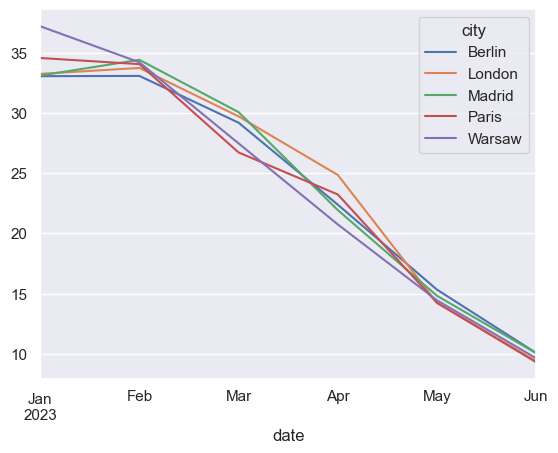

In [65]:
my_plot = df.groupby('city')['pm25'].resample(
            'ME').mean().unstack(0).plot(legend=True)
my_plot

14

<Axes: xlabel='Cities', ylabel='AVG PM 2.5'>

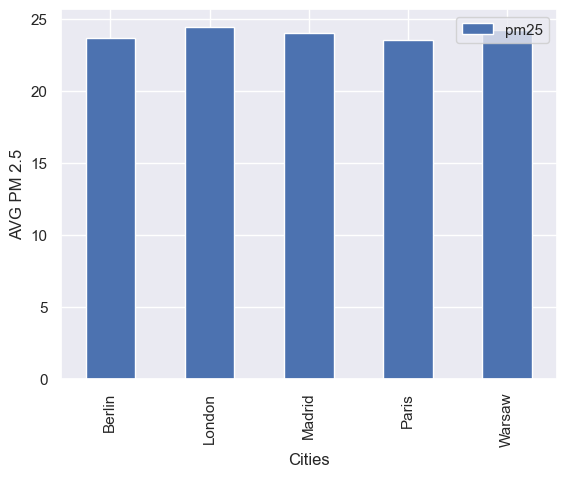

In [66]:
my_bar = df.pivot_table(values = 'pm25',
                        index = 'city',
                        aggfunc='mean').plot(kind='bar', ylabel='AVG PM 2.5', xlabel='Cities', legend=True)
my_bar

15

<Figure size 1000x500 with 0 Axes>

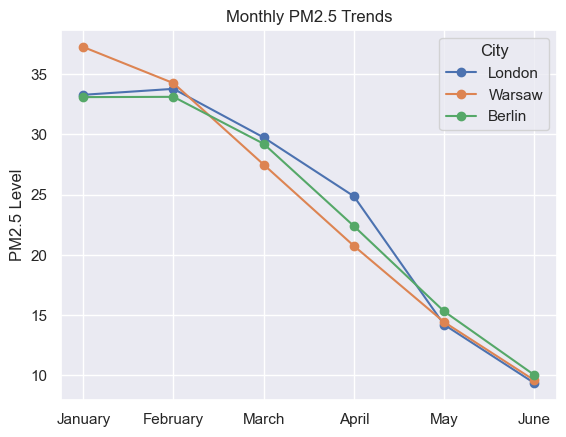

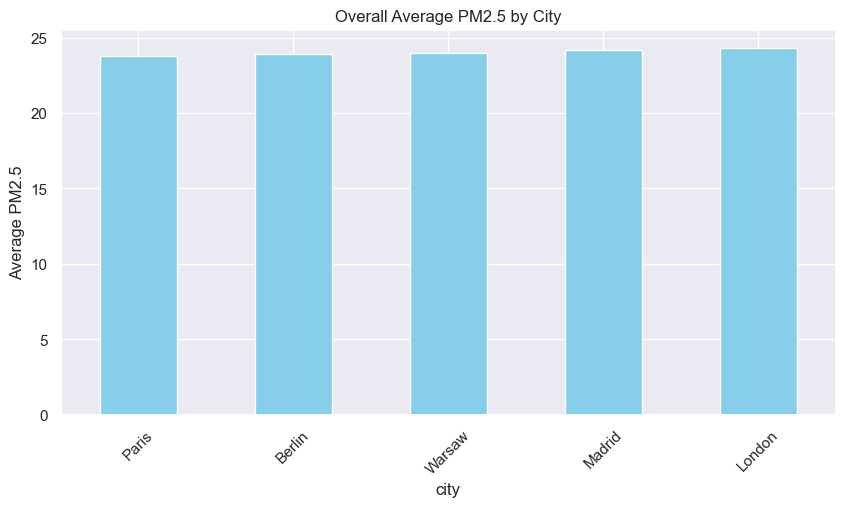

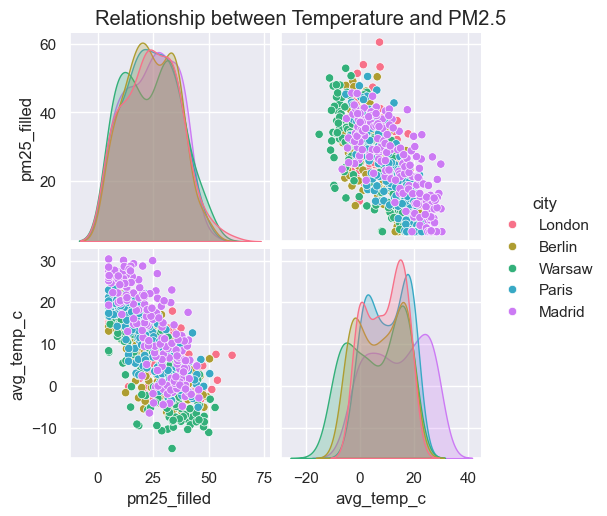

In [67]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
monthly_avg[['London', 'Warsaw', 'Berlin']].plot(kind='line', marker='o')
plt.title('Monthly PM2.5 Trends')
plt.ylabel('PM2.5 Level')
plt.legend(title='City')
plt.show() 

plt.figure(figsize=(10, 5))
df.groupby('city')['pm25_filled'].mean().sort_values().plot(kind='bar', color='skyblue')
plt.title('Overall Average PM2.5 by City')
plt.ylabel('Average PM2.5')
plt.xticks(rotation=45)
plt.show()

sns.set_theme(style='darkgrid')
g = sns.pairplot(df.reset_index(), 
                 vars=['pm25_filled', 'avg_temp_c'], 
                 hue='city', 
                 palette='husl', 
                 diag_kind='kde')
g.fig.suptitle('Relationship between Temperature and PM2.5', y=1.02)
plt.show()

## Part E: Interpretation Questions (TODOs)

Write short answers here:

1. Which city shows the most persistent high pm25 levels, and what evidence supports that?
2. How does missing or invalid data affect your confidence in the results?
3. Does temperature appear related to pm25 in your analysis? Explain briefly.
4. What is one limitation of using daily averages for air-quality policy decisions?
5. If you had one more dataset to improve this analysis, what would it be and why?

1. London, it has the highest avg and max pm25. I have done the both visualization and outputs for that information based on the given csv.

2. The dataset is missing 50 PM2.5​ readings and 37 temperature records. as the missing data is random(not sequential)it weakens the confidence

3. Theres a negative correlation between temperature and pm25. when temp is low the pm25 is higher.

4. Daily avg smooths the peaks. for example the air pollution distribution is higher in rush hours, but in avg its smoothed, for health policy its better to have information about max hourly exposure.

5. wind speed and direction, as wind has a role in cleaning the air. as pollution is dynamic and wind is one of the factors of it, it would be better to have it in dataset for both predictions and cleaner overview.